# 09tracks: typhoons and climate indices, 2003 to 2026

Part C of PF5 (the climatology, the seed for the paper). This notebook prepares everything except the aerosol data (that is `10merra2`):

| Section | What | Download |
|---|---|---|
| 2 | IBTrACS western Pacific best tracks (all years) | one file, about 50 to 100 MB, a few minutes |
| 3 | Typhoon days for every August to October since 2003, with the same definition as `06season` | none |
| 4 | El Nino (ONI) and Indian Ocean Dipole (DMI) indices, which steer how bad a haze year is | two small text files |
| 5 | Charts: typhoon days per season, and where the typhoons went | none |

**Why 2003.** MODIS fire data and good satellite aerosol data going into MERRA-2 start around then, and 2003 to 2025 gives 23 complete seasons including the big haze years 2006, 2015, 2019 and 2023.

## Section 0: settings

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw" / "climatology"
OUT_DIR = PROJECT_DIR / "data" / "processed" / "climatology"
FIG_DIR = OUT_DIR / "figures"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"

FIRST_YEAR = 2003  # <-
LAST_YEAR = 2026  # <- 2026 is incomplete (to the latest track in the file)
SEASON_MONTHS = [8, 9, 10]  # <- August to October

TC_MIN_KT = 64  # <- same as 06season
TC_BOX = (120.0, 150.0, 5.0, 25.0)  # <- Philippine Sea (west, east, south, north), same as 06season

IBTRACS_URL = "https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.WP.list.v04r01.csv"  # <-
ONI_URL = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"  # <- NOAA CPC Oceanic Nino Index
DMI_URL = "https://psl.noaa.gov/gcos_wgsp/Timeseries/Data/dmi.had.long.data"  # <- NOAA PSL Dipole Mode Index (HadISST)
HAZE_YEARS = [2006, 2015, 2019, 2023]  # <- VISUAL: well-known bad haze years, marked on the charts

## Section 1: imports

In [3]:
import io
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for d in [RAW_DIR, OUT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10


def fetch(url, path, timeout=600):
    if path.exists() and path.stat().st_size > 0:
        print(f"{path.name}: already there ({path.stat().st_size / 1e6:.1f} MB)")
        return
    with requests.get(url, stream=True, timeout=timeout) as r:
        print(f"{path.name}: HTTP {r.status_code}")
        r.raise_for_status()
        with open(path, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

## Section 2: IBTrACS western Pacific

In [4]:
ib_file = RAW_DIR / "ibtracs_WP.csv"
fetch(IBTRACS_URL, ib_file)
ib = pd.read_csv(ib_file, skiprows=[1], low_memory=False, usecols=lambda c: c in ["SID", "SEASON", "NAME", "ISO_TIME", "NATURE", "LAT", "LON", "USA_WIND", "USA_PRES", "WMO_WIND", "TOKYO_WIND"])
ib["time"] = pd.to_datetime(ib["ISO_TIME"])
ib["wind"] = pd.to_numeric(ib["USA_WIND"], errors="coerce")
ib["LAT"] = pd.to_numeric(ib["LAT"], errors="coerce")
ib["LON"] = pd.to_numeric(ib["LON"], errors="coerce")
ib = ib[(ib["time"].dt.year >= FIRST_YEAR) & (ib["time"].dt.year <= LAST_YEAR)].copy()
print("Track points", FIRST_YEAR, "to", LAST_YEAR, ":", len(ib), " storms:", ib["SID"].nunique(), " latest point:", ib["time"].max())

ibtracs_WP.csv: HTTP 200
ibtracs_WP.csv: 114.7 MB
Track points 2003 to 2026 : 47149  storms: 720  latest point: 2026-10-29 00:00:00


## Section 3: typhoon days per season

A day is a typhoon day when a system of at least 64 knots has a track point in the Philippine Sea box that day (as in `06season`). The table also counts the storms involved and an "intensity-days" sum (number of 6-hourly typhoon points in the box divided by 4), which grows with both duration and number of typhoons.

In [9]:
in_box = ib["LON"].between(TC_BOX[0], TC_BOX[1]) & ib["LAT"].between(TC_BOX[2], TC_BOX[3]) & (ib["wind"] >= TC_MIN_KT)
tc_pts = ib[in_box].copy()
tc_pts["day"] = tc_pts["time"].dt.normalize()
six_hourly = tc_pts[tc_pts["time"].dt.hour.isin([0, 6, 12, 18])]

all_days = pd.DatetimeIndex([d for y in range(FIRST_YEAR, LAST_YEAR + 1) for d in pd.date_range(f"{y}-{SEASON_MONTHS[0]:02d}-01", (pd.Timestamp(f"{y}-{SEASON_MONTHS[-1]:02d}-01") + pd.offsets.MonthEnd(0)))])
all_days = all_days[all_days <= ib["time"].max().normalize()]
names = tc_pts.groupby("day")["NAME"].agg(lambda s: ", ".join(sorted(set(s))))
maxw = tc_pts.groupby("day")["wind"].max()
days = pd.DataFrame(index=all_days)
days["typhoon_day"] = days.index.isin(names.index)
days["storms"] = names.reindex(days.index).fillna("")
days["max_wind_kt"] = maxw.reindex(days.index)
days.index.name = "date"
days.to_csv(OUT_DIR / "typhoon_days.csv")

season = days.groupby(days.index.year).agg(days=("typhoon_day", "size"), typhoon_days=("typhoon_day", "sum"))
season["storms"] = tc_pts[tc_pts["time"].dt.month.isin(SEASON_MONTHS)].groupby(tc_pts["time"].dt.year)["SID"].nunique()
season["intensity_days"] = six_hourly[six_hourly["time"].dt.month.isin(SEASON_MONTHS)].groupby(six_hourly["time"].dt.year).size() / 4
season = season.fillna(0)
season["typhoon_day_pct"] = 100 * season["typhoon_days"] / season["days"]
season.index.name = "year"
season.to_csv(OUT_DIR / "typhoon_season_summary.csv")
print(f"Typhoon days in August to October, Philippine Sea box, at least {TC_MIN_KT} kt:")
print(season.round(1).to_string())
print()
full = season.loc[FIRST_YEAR:2025]
print(f"{FIRST_YEAR} to 2025: mean {full['typhoon_days'].mean():.1f} typhoon days per season (range {full['typhoon_days'].min():.0f} to {full['typhoon_days'].max():.0f}); total typhoon days {int(full['typhoon_days'].sum())}, other days {int((full['days'] - full['typhoon_days']).sum())}")

Typhoon days in August to October, Philippine Sea box, at least 64 kt:
      days  typhoon_days  storms  intensity_days  typhoon_day_pct
year                                                             
2003    92            22       8            17.2             23.9
2004    92            34       8            31.0             37.0
2005    92            31       8            26.8             33.7
2006    92            21       6            14.8             22.8
2007    92            19       6            13.2             20.7
2008    92            15       4            12.2             16.3
2009    92            28       6            25.0             30.4
2010    92            16       5            12.0             17.4
2011    92            17       5            13.5             18.5
2012    92            29       6            26.5             31.5
2013    92            29      11            23.0             31.5
2014    92            19       4            15.8             20.7
2015 

## Section 4: El Nino and Indian Ocean Dipole

- **ONI** (Oceanic Nino Index, NOAA CPC): 3-month running sea surface temperature anomaly in the central Pacific. El Nino (ONI 0.5 or more) usually means a drier, worse fire season in Indonesia.
- **DMI** (Dipole Mode Index): positive Indian Ocean Dipole also dries Sumatra and Kalimantan.

Both are kept as monthly values and as the August to October mean of each year.

In [10]:
oni_file = RAW_DIR / "oni.ascii.txt"
dmi_file = RAW_DIR / "dmi.had.long.data"
fetch(ONI_URL, oni_file, 120)
fetch(DMI_URL, dmi_file, 120)

oni = pd.read_csv(oni_file, sep=r"\s+")
season_mid = {"JAS": 8, "ASO": 9, "SON": 10}
oni_aso = oni[oni["SEAS"].isin(["JAS", "ASO", "SON"])].groupby("YR")["ANOM"].mean().rename("oni_aso")

dmi_rows = []
for line in dmi_file.read_text().splitlines()[1:]:
    parts = line.split()
    if len(parts) == 13 and parts[0].isdigit():
        dmi_rows.append([int(parts[0])] + [float(p) for p in parts[1:]])
dmi = pd.DataFrame(dmi_rows, columns=["year"] + list(range(1, 13))).set_index("year")
dmi = dmi.where(dmi > -90)
dmi_aso = dmi[SEASON_MONTHS].mean(axis=1).rename("dmi_aso")

idx = pd.concat([oni_aso, dmi_aso], axis=1).loc[FIRST_YEAR:LAST_YEAR]
idx.index.name = "year"
season = season.join(idx)
season.to_csv(OUT_DIR / "typhoon_season_summary.csv")
print("August to October means (ONI in C, DMI in C):")
print(idx.round(2).to_string())

oni.ascii.txt: already there (0.0 MB)
dmi.had.long.data: already there (0.0 MB)
August to October means (ONI in C, DMI in C):
      oni_aso  dmi_aso
year                  
2003     0.20    -0.06
2004     0.58    -0.08
2005    -0.17    -0.44
2006     0.53     0.41
2007    -1.07     0.18
2008    -0.27     0.08
2009     0.71    -0.07
2010    -1.40    -0.26
2011    -0.73     0.30
2012     0.35     0.40
2013    -0.27    -0.22
2014     0.27    -0.13
2015     2.01     0.45
2016    -0.42    -0.42
2017    -0.25     0.13
2018     0.55     0.47
2019     0.34     0.76
2020    -0.73    -0.10
2021    -0.62    -0.08
2022    -0.85    -0.42
2023     1.50     0.86
2024    -0.12     0.06
2025    -0.42    -0.44
2026     2.16      NaN


## Section 5: charts

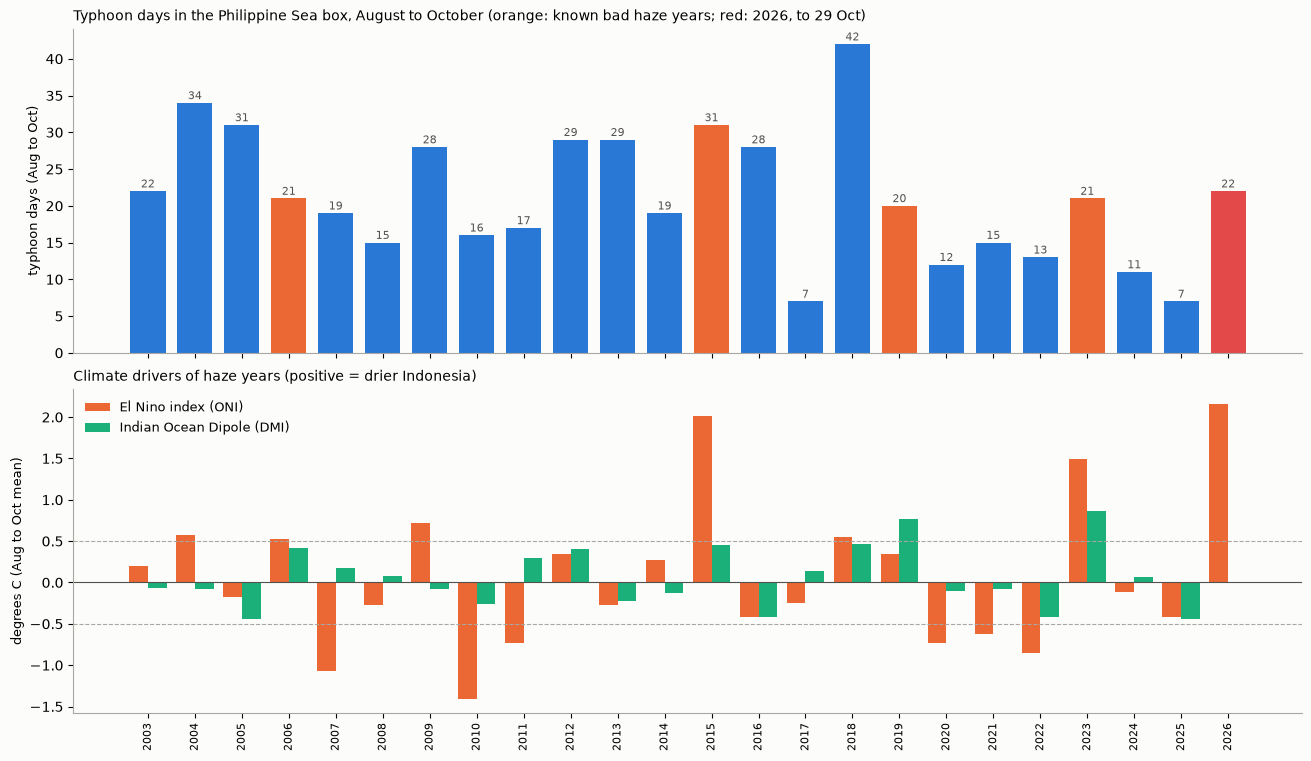

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, constrained_layout=True)
yrs = season.index.values
ax = axes[0]
colors = ["#e34948" if y == 2026 else ("#eb6834" if y in HAZE_YEARS else "#2a78d6") for y in yrs]
ax.bar(yrs, season["typhoon_days"], color=colors, width=0.75)
for y, v in zip(yrs, season["typhoon_days"]):
    ax.text(y, v + 0.5, f"{v:.0f}", ha="center", fontsize=8, color="#52514e")
ax.set_ylabel("typhoon days (Aug to Oct)", fontsize=9)
ax.set_title(f"Typhoon days in the Philippine Sea box, August to October (orange: known bad haze years; red: 2026, to {ib['time'].max():%d %b})", loc="left", fontsize=10)
ax = axes[1]
ax.bar(yrs - 0.2, season["oni_aso"], width=0.4, color="#eb6834", label="El Nino index (ONI)")
ax.bar(yrs + 0.2, season["dmi_aso"], width=0.4, color="#1baf7a", label="Indian Ocean Dipole (DMI)")
ax.axhline(0, color="#52514e", lw=0.8)
ax.axhline(0.5, color="#a8a7a2", lw=0.8, ls="--")
ax.axhline(-0.5, color="#a8a7a2", lw=0.8, ls="--")
ax.set_ylabel("degrees C (Aug to Oct mean)", fontsize=9)
ax.set_title("Climate drivers of haze years (positive = drier Indonesia)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
axes[1].set_xticks(yrs)
axes[1].tick_params(axis="x", rotation=90, labelsize=8)
fig.savefig(FIG_DIR / "typhoon_days_by_season.png", dpi=110)
plt.show()

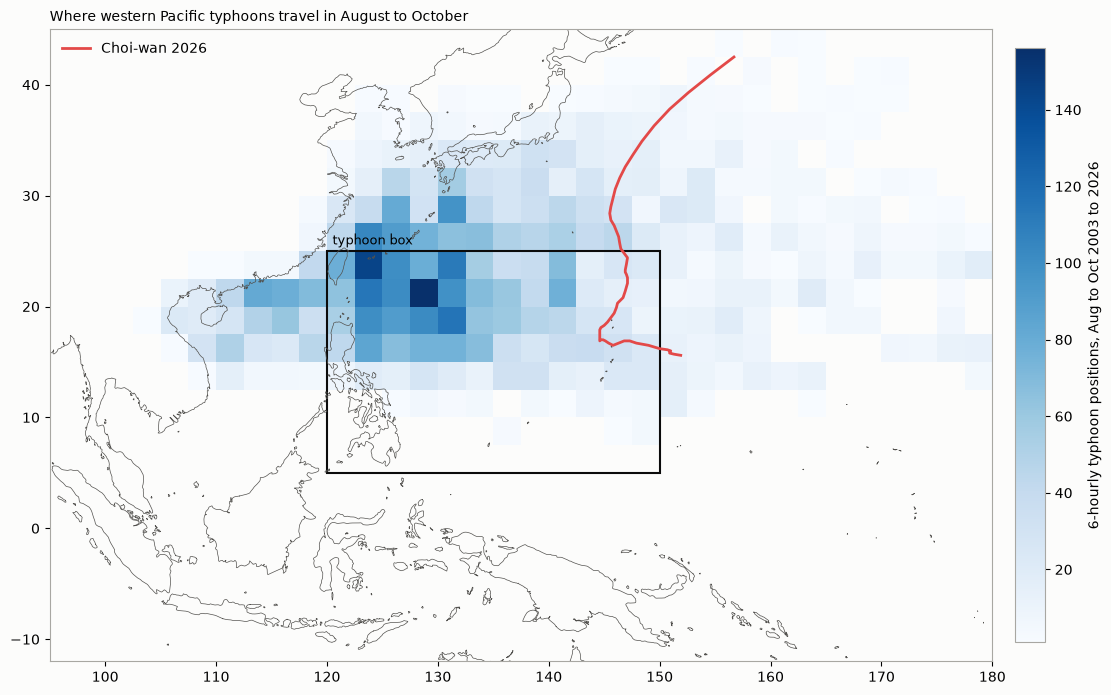

In [8]:
coast = []
for feat in json.loads((COAST_DIR / "ne_50m_coastline.geojson").read_text(encoding="utf8"))["features"]:
    g = feat["geometry"]
    coast += [np.array(c) for c in (g["coordinates"] if g["type"] == "MultiLineString" else [g["coordinates"]])]
sub = ib[ib["time"].dt.month.isin(SEASON_MONTHS) & (ib["wind"] >= TC_MIN_KT)]
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
h = ax.hist2d(sub["LON"], sub["LAT"], bins=[np.arange(100, 181, 2.5), np.arange(0, 46, 2.5)], cmap="Blues", cmin=1)
fig.colorbar(h[3], ax=ax, shrink=0.75, pad=0.01).set_label(f"6-hourly typhoon positions, Aug to Oct {FIRST_YEAR} to {LAST_YEAR}")
for line in coast:
    ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
ax.add_patch(plt.Rectangle((TC_BOX[0], TC_BOX[2]), TC_BOX[1] - TC_BOX[0], TC_BOX[3] - TC_BOX[2], fill=False, lw=1.5, ec="#0b0b0b"))
ax.text(TC_BOX[0] + 0.5, TC_BOX[3] + 0.6, "typhoon box", fontsize=9)
cw = ib[ib["NAME"] == "CHOI-WAN"]
cw = cw[cw["time"].dt.year == 2026]
if len(cw):
    ax.plot(cw["LON"], cw["LAT"], color="#e34948", lw=2, label="Choi-wan 2026")
    ax.legend(frameon=False, loc="upper left")
ax.set_xlim(95, 180)
ax.set_ylim(-12, 45)
ax.set_aspect("equal")
ax.set_title("Where western Pacific typhoons travel in August to October", loc="left", fontsize=10)
fig.savefig(FIG_DIR / "typhoon_track_density.png", dpi=110)
plt.show()

___
**END**